# Predicción de la calidad del vino
*Autores: Breixo Parada López, Marco Somoza López*



# Análisis de datos y visualización

En el siguiente proyecto de machine learning se estima la calidad de un vino (en una escala del 3 a 8) en función de 11 diferentes propiedades químicas tales como el pH o el alcohol.

Es un problema de clasificación en el que el dataset nos da un conjunto de propiedades y, mediante implementación de algoritmos de ML, obtenemos la calidad de cada vino clasificándolo como 'bueno' o 'malo'.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import time
import random

random.seed(100)

Acabamos de importar las librerías que necesitaremos más adelante. Vamos a añadir ahora nuestra base de datos.

In [2]:
vino = pd.read_csv('calidadvino.csv')

In [3]:
vino.head()

,acidez fija,acidez volátil,acido cítrico,azúcar residual,cloruros,dióxido de azufre libre,dióxido de azufre total,densidad,pH,sulfatos,alcohol,calidad
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [4]:
vino.isna().any()

acidez fija                False
acidez volátil             False
acido cítrico              False
azúcar residual            False
cloruros                   False
dióxido de azufre libre    False
dióxido de azufre total    False
densidad                   False
pH                         False
sulfatos                   False
alcohol                    False
calidad                    False
dtype: bool

In [5]:
vino.duplicated().sum()

np.int64(240)

Como vemos no hay ningún dato faltante, pero sí tenemos datos duplicados. Esto último puede desencadenar que una muestra caiga en entrenamiento y prueba (como haremos más adelante) y el modelo puede memorizarla. Para solucionar este problema eliminamos esos valores.

In [6]:
vino = vino.drop_duplicates().reset_index(drop=True)
print(vino.shape)

(1359, 12)


In [7]:
vino.describe()

,acidez fija,acidez volátil,acido cítrico,azúcar residual,cloruros,dióxido de azufre libre,dióxido de azufre total,densidad,pH,sulfatos,alcohol,calidad
count,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000
mean,8.310596,0.529478,0.272333,2.523400,0.088124,15.893304,46.825975,0.996709,3.309787,0.658705,10.432315,5.623252
std,1.736990,0.183031,0.195537,1.352314,0.049377,10.447270,33.408946,0.001869,0.155036,0.170667,1.082065,0.823578
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996700,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.430000,2.600000,0.091000,21.000000,63.000000,0.997820,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [8]:
vino['calidad'].value_counts().sort_index()

calidad
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64

Podemos ver que hay muy pocos vinos con un 3 o con un 8. Algunas clases tienen muy pocos ejemplos y un modelo tendrá más dificultades en reconocerlas. Por ello es más conveniente reducir el número de clases y aumentar así la muestra de cada una. Esto lo haremos clasificando en malo o bueno.

In [9]:
bins = (2, 6.5, 8)
#catalogamos del 3 al 6 como malos y del 7 al 8 como buenos
group_names = ['malo', 'bueno']
vino['calidad'] = pd.cut(vino['calidad'], bins = bins, labels = group_names)
#cada valor se asigna a los nombres
vino['calidad'] = vino['calidad'].map({'malo': 0, 'bueno': 1})
#Asignamos 0 a 'malo' y 1 a 'bueno'
vino['calidad'].value_counts()

calidad
0    1175
1     184
Name: count, dtype: int64

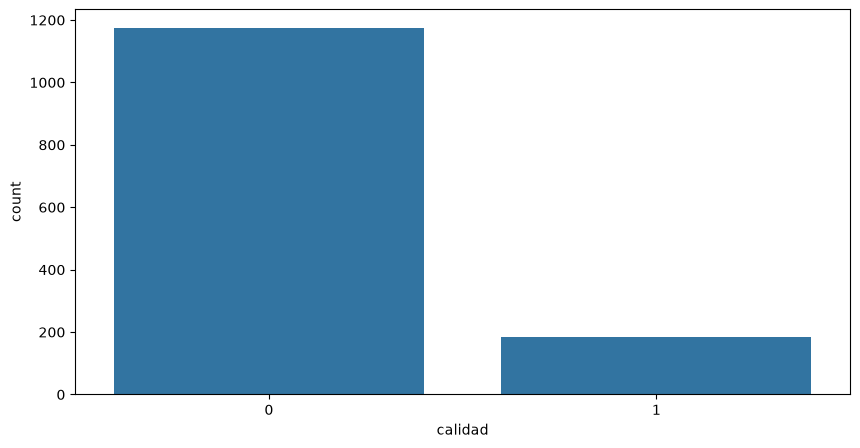

In [10]:
plt.figure(figsize=(10, 5))
sns.countplot(x='calidad', data=vino)
plt.show()

Ahora representamos las variables comparadas consigo mismas (un histograma) y con el resto (un gráfico de dispersión)

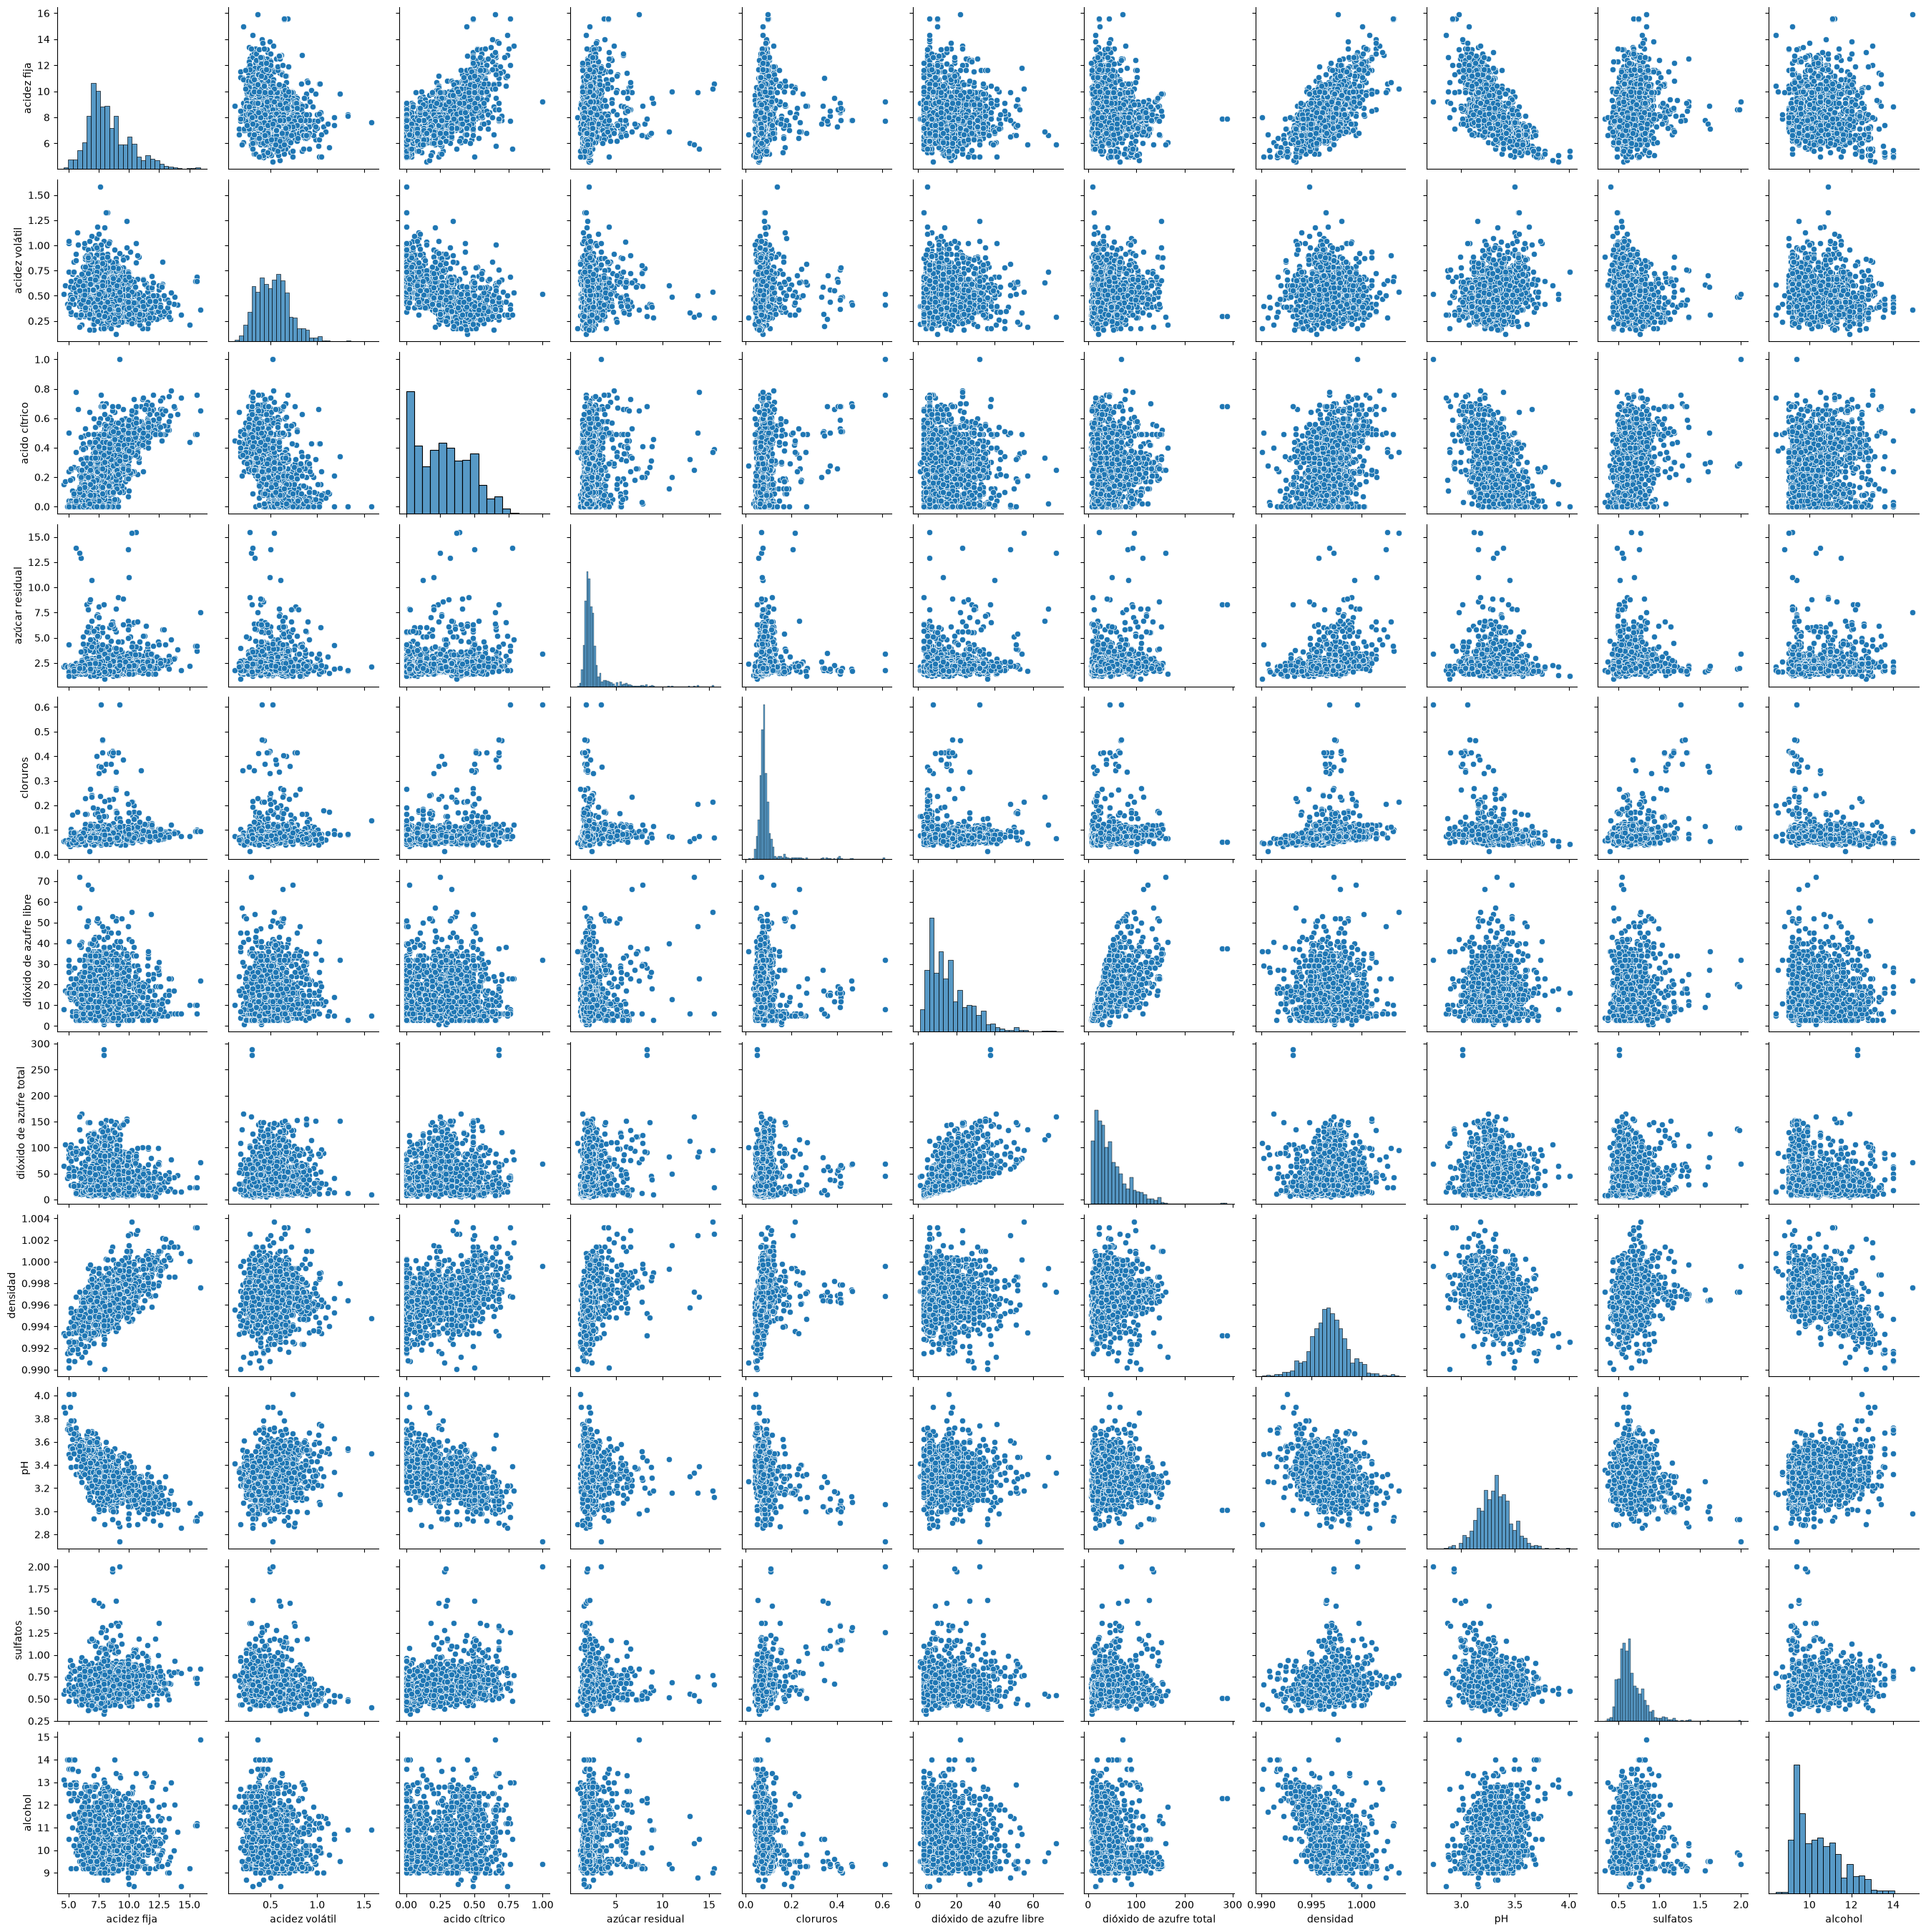

In [11]:
sns.pairplot(vino)
plt.show()

Ahora mostramos la correlación del resto de variables con la calidad mediante otro gráfico

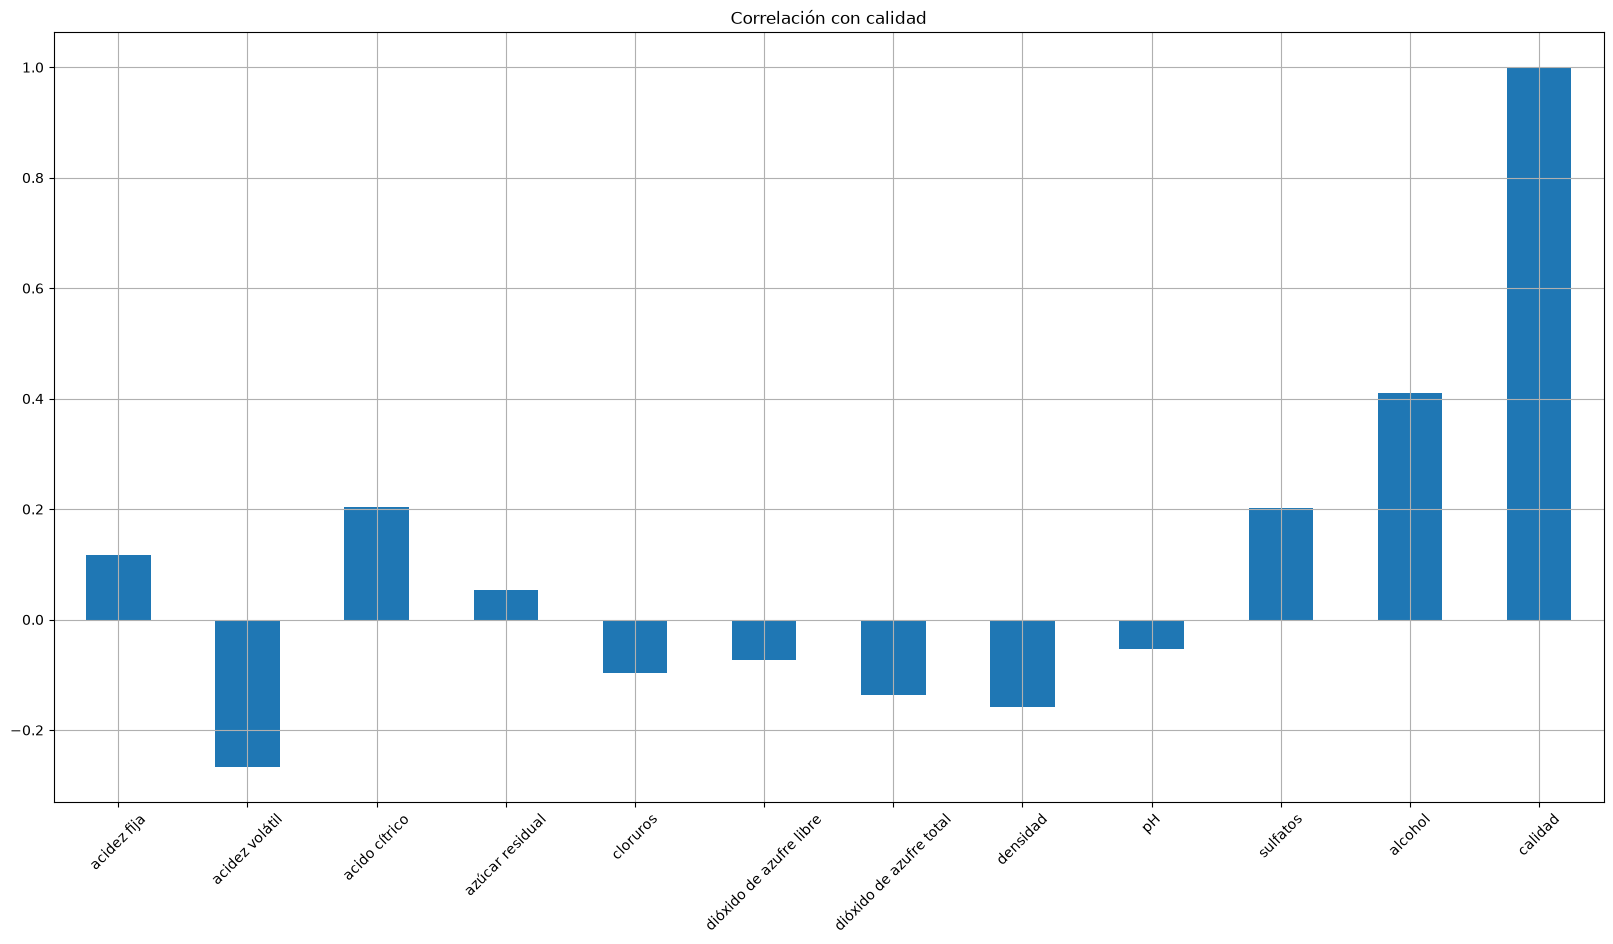

In [12]:
vino.corrwith(vino.calidad).plot.bar(
        figsize = (20, 10), title = "Correlación con calidad",
        grid = True, rot = 45)
plt.show()

In [13]:
#Matriz de correlación
corr = vino.corr()
print(corr.to_string())

                         acidez fija  acidez volátil  acido cítrico  azúcar residual  cloruros  dióxido de azufre libre  dióxido de azufre total  densidad        pH  sulfatos   alcohol   calidad
acidez fija                 1.000000       -0.255124       0.667437         0.111025  0.085886                -0.140580                -0.103777  0.670195 -0.686685  0.190269 -0.061596  0.116120
acidez volátil             -0.255124        1.000000      -0.551248        -0.002449  0.055154                -0.020945                 0.071701  0.023943  0.247111 -0.256948 -0.197812 -0.267344
acido cítrico               0.667437       -0.551248       1.000000         0.143892  0.210195                -0.048004                 0.047358  0.357962 -0.550310  0.326062  0.105108  0.203561
azúcar residual             0.111025       -0.002449       0.143892         1.000000  0.026656                 0.160527                 0.201038  0.324522 -0.083143 -0.011837  0.063281  0.052811
cloruros                 

Donde se puede apreciar que la variable que más determina la calidad de un vino es su porcentaje de alcohol.

# Implementación del modelo

En la presente sección vamos a preparar y a transformar las variables que nos da de entrada el dataset para que el modelo pueda aprender mejor.

Por ejemplo, si las variables están muy relacionadas entre sí o tienen escalas muy distintas el modelo puede aprender peor aunque el algoritmo sea correcto.

En nuestro proyecto aplicaremos las siguientes transformaciones:
*   Seleccionar variables para dividirlas entre las de entrada y las que queremos calcular
*   Dividir la muestra en datos de entrenamiento y de prueba (80%/20%)
*   Situar todas las variables en una escala comparable
*   Reducir el número de variables

Primero dividimos las variables que nos da el dataset en variables que el modelo usará como entrada (X) y la variable que queremos predecir (y):

In [14]:
X = vino.drop('calidad',axis=1) #con axis=1 eliminamos una columna, no una fila
y=vino['calidad']

Comprobamos el resultado de la división que acabamos de hacer:

In [15]:
X.head()

,acidez fija,acidez volátil,acido cítrico,azúcar residual,cloruros,dióxido de azufre libre,dióxido de azufre total,densidad,pH,sulfatos,alcohol
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4


In [16]:
y.head()

0    0
1    0
2    0
3    0
4    0
Name: calidad, dtype: category
Categories (2, int64): [0 < 1]

Con esto vemos que X no tiene la columna "calidad" e y contiene solo esa columna.

In [17]:
print(vino.columns[:11])
etiquetas = vino.columns[:11]

Index(['acidez fija', 'acidez volátil', 'acido cítrico', 'azúcar residual',
       'cloruros', 'dióxido de azufre libre', 'dióxido de azufre total',
       'densidad', 'pH', 'sulfatos', 'alcohol'],
      dtype='str')


A continuación construimos un Random Forest para determinar la importancia de cada variable:

In [18]:
from sklearn.ensemble import RandomForestClassifier
clasificador = RandomForestClassifier(n_estimators = 200, criterion = 'entropy',
                                      random_state = 0)
clasificador.fit(X, y)
importancias = clasificador.feature_importances_
indices = np.argsort(importancias)[::-1]
#aquí devolvemos los valores ordenados de mayor a menor importancia


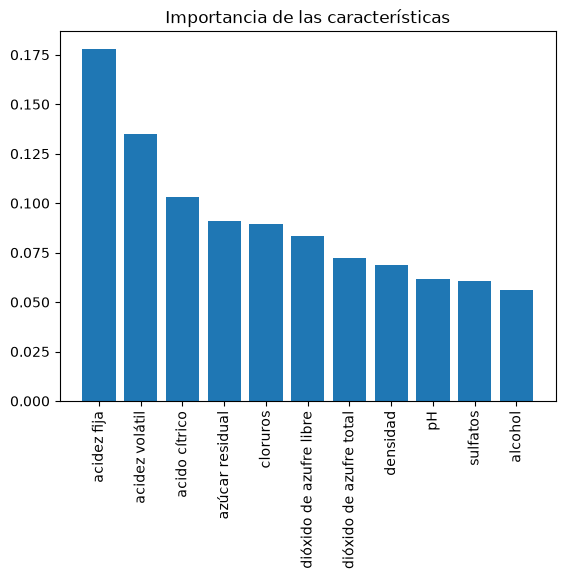

In [19]:
plt.title('Importancia de las características')
plt.bar(range(X.shape[1]),importancias[indices])
plt.xticks(range(X.shape[1]),etiquetas, rotation=90)
plt.show()

Esta gráfica determina que la acidez fija es la variable que más aporta en el modelo. Esto contrasta con el hecho de que el alcohol es la más correlacionada con la calidad, lo cual se debe a que la correlación mide cuán relacionada está cada variable por separado con la calidad. No obstante, en el Random Forest se tiene en cuenta lo que aportan las demás. Por ejemplo, como la densidad y el alcohol están fuertemente correlacionados, un árbol obtiene casi la misma información usando la densidad que usando el alcohol.

Ahora, dividiremos el conjunto de datos en conjunto de entrenamiento y conjunto de prueba.

In [20]:
from sklearn.model_selection  import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20,
                                                    random_state = 5)

Para evitar que unas variables tengan más peso que otras simplemente porque sus valores son más grandes pondremos todas las variables numéricas en una escala similar. En concreto, StandardScaler transforma cada variable para que tenga media 0 y desviación típica 1.

In [21]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train2 = pd.DataFrame(sc.fit_transform(X_train))
X_test2 = pd.DataFrame(sc.transform(X_test))
#restauramos los nombres e índices originales de cada variable, porque
#fit_transform devuelve una matriz sin nombres
X_train2.columns = X_train.columns.values
X_test2.columns = X_test.columns.values
X_train2.index = X_train.index.values
X_test2.index = X_test.index.values
#actualizamos valores
X_train = X_train2
X_test = X_test2

Mediante un PCA (Principal Component Analysis) reducimos la dimensionalidad con el objetivo de reducir el número de variables intentando conservar la mayor cantidad posible de información.

In [22]:
from sklearn.decomposition import PCA
pca = PCA(n_components = 4)
X_train = pca.fit_transform(X_train)
X_test = pca.transform(X_test)
varianza = pca.explained_variance_ratio_
print(pd.DataFrame(varianza))

          0
0  0.286838
1  0.173603
2  0.136883
3  0.114020


Reducimos el conjunto de 11 variables a solamente 4. La salida muestra cuánta varianza explica cada nueva variable. Por tanto deducimos que en total explican un 71% de la información original y el modelo, pese a reducir la dimensionalidad de 11 a 4 variables, pierde un 29% de la información.

Finalmente procedemos a construir los modelos y compararlos entre ellos. Usaremos una regresión logística, un SVM (Support Vector Machine) y un Random Forest.

En primer lugar utilizaremos una regresión logística. Este algoritmo calcula la combinación lineal de las variables de entrada, la transforma mediante una función sigmoide (del tipo $σ(x)=\frac{1}{1+e^{-x}}$) y devuelve una probabilidad entre 0 y 1, y si la probabilidad supera un umbral, asigna una categoría. Empezamos por este modelo porque es sencillo y rápido.

In [23]:
from sklearn.linear_model import LogisticRegression
clasificador = LogisticRegression(random_state = 0)
clasificador.fit(X_train, y_train)

# Realizar predicciones sobre el conjunto de prueba
y_pred = clasificador.predict(X_test)
#predict devuelve la clase para cada vino
#si la probabilidad de "bueno" es mayor o igual que 0.5 predice 1, si no da 0

from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, precision_score, recall_score

acc = accuracy_score(y_test, y_pred)
#¿qué proporción de vinos el modelo clasifica bien?

prec = precision_score(y_test, y_pred)
#de los vinos que el modelo marcó como buenos ¿cuántos lo eran?

rec = recall_score(y_test, y_pred)
#sensibilidad. De los vinos buenos ¿cuántos encontró el modelo?

f1 = f1_score(y_test, y_pred)
#media armónica de precision y recall

res = pd.DataFrame([['Regresión logística', acc, prec, rec, f1]],
               columns = ['Modelo', 'Accuracy', 'Precision', 'Recall',
                          'Puntuación F1'])
print(res)

                Modelo  Accuracy  Precision  Recall  Puntuación F1
0  Regresión logística  0.871324   0.619048   0.325        0.42623


A partir de estos resultados podemos inferir que el modelo tiene buena accuracy, no obstante debemos tener en cuenta que un modelo que asigne a todos como "malos" tendría un 85%, y por tanto no es algo destacable. Además, falla al encontrar los vinos buenos (encuentra 1 de cada 3). Por tanto el modelo aprende correctamente a identificar los malos, que son la mayor parte, pero pasa por alto muchos buenos (que son el 13% de la muestra).

En segundo lugar, implementamos el modelo SVM lineal. Este algoritmo es un clasificador que busca la mejor frontera entre clases. Lo hace buscando un hiperplano óptimo que separe los puntos de distintas categorías maximizando la distancia entre el hiperplano y las observaciones más cercanas de cada clase (los vectores de soporte). Se usa para predecir a que categoría pertenecerá un nuevo punto.

In [24]:
from sklearn.svm import SVC
clasificador = SVC(random_state = 0, kernel = 'linear')
#con el kernel lineal la frontera entre clases es una recta
clasificador.fit(X_train, y_train)

# Realizar predicciones sobre el conjunto de prueba
y_pred = clasificador.predict(X_test)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

res = pd.DataFrame([['SVM (Lineal)', acc, prec, rec, f1]],
               columns = ['Modelo', 'Accuracy', 'Precision', 'Recall',
                          'Puntuación F1'])
print(res)

         Modelo  Accuracy  Precision  Recall  Puntuación F1
0  SVM (Lineal)  0.852941        0.0     0.0            0.0


c:\Users\Usuario\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


Como vemos, el recall y precision son 0. Por tanto este modelo no clasifica como bueno ningún vino.

Ahora presentamos el modelo SVM RBF (Radial Basis Function), que permite encontrar fronteras de decisión no lineales.

In [25]:
from sklearn.svm import SVC
clasificador = SVC(random_state = 0, kernel = 'rbf')
clasificador.fit(X_train, y_train)

# Realizar predicciones sobre el conjunto de prueba
y_pred = clasificador.predict(X_test)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

res = pd.DataFrame([['SVM (RBF)', acc, prec, rec, f1]],
               columns = ['Modelo', 'Accuracy', 'Precision', 'Recall',
                          'Puntuación F1'])
print(res)

      Modelo  Accuracy  Precision  Recall  Puntuación F1
0  SVM (RBF)  0.871324   0.692308   0.225       0.339623


Este modelo es mejor que el SVM lineal pero detecta muy pocos vinos buenos (solo un 22%).

Por último, empleamos el modelo de bosque aleatorio (Random Forest). Este algoritmo construye árboles de decisión individuales. Cada árbol se entrena con una muestra aleatoria y, en cada división de los nodos del árbol, se evalúa un subconjunto aleatorio de variables (así se reduce la correlación entre los árboles), luego el bosque recopila todas las respuestas y decide el resultado final por votación.

In [26]:
from sklearn.ensemble import RandomForestClassifier
clasificador = RandomForestClassifier(random_state = 0, n_estimators = 100,
                                    criterion = 'entropy')
clasificador.fit(X_train, y_train)

# Realizar predicciones sobre el conjunto de prueba
y_pred = clasificador.predict(X_test)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

res = pd.DataFrame([['Bosque aleatorio (n=100)', acc, prec, rec, f1]],
               columns = ['Modelo', 'Accuracy', 'Precision', 'Recall',
                          'Puntuación F1'])
print(res)

                     Modelo  Accuracy  Precision  Recall  Puntuación F1
0  Bosque aleatorio (n=100)  0.867647   0.583333    0.35         0.4375


Ahora representamos los resultados obtenidos por los cuatro modelos:

| Modelo              | Accuracy | Precision | Recall | Puntuación F1 |
|:-------------------:|:--------:|:---------:|:------:|:-------------:|
| Regresión Logística | 0,871    | 0,619     | 0,325   | 0,426         |
| SVM lineal          | 0,853    | 0,000     | 0,000   | 0,000         |
| SVM rbf             | 0,871    | 0,692     | 0,225   | 0,340         |
| Bosque aleatorio    | 0,868    | 0,583     | 0,350   | 0,438         |

Ahora podemos apreciar que el Random Forest obtiene el mejor F1 y recall (encuentra más vinos buenos), aunque la diferencia con la regresión logística y el SVM RBF es pequeña. Además podemos inferir que el SVM lineal no sirve para esta clase (predice siempre "malo").